# El enfoque del sustituto aprendido frente a la planta: lo que un puntaje de muestra de prueba no dice

**Pregunta:** La práctica publicada juzga un sustituto aprendido de un modelo de conminución por su error frente a ese modelo; ¿qué dice el mismo sustituto de los diez muestreos reales del HP500, y avisa el autoencoder del producto cuando el sustituto está fuera de su dominio?

- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** el notebook 02 de este tema y el notebook 01 del tema 05-real-surveys
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook usted puede:

- enunciar qué afirma el trabajo publicado sobre sustitutos aprendidos y cómo se valida;
- aplicar ese mismo enfoque, el sustituto propio del producto, a los diez muestreos y compararlo con la medición;
- encontrar el rango de entradas donde la red deja de ser un modelo del motor, y mostrar qué devuelve fuera de él;
- decir si el autoencoder del producto avisa en ese punto, a qué responden sus alarmas en los muestreos, y qué implica eso para cómo puede usarse el sustituto.

## Preparación

Las mismas cuatro bibliotecas del resto del tema.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

Las importaciones agregan el lector de muestreos y el punto de operación de la vía calibrada del tema 05, los lectores de la red cruda y del autoencoder, la regla de aplicabilidad y los rangos de la barrida del dominio de entrenamiento, con la métrica de error pública de CrusherCal.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from collections import Counter
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import loo
from pipeline.model import sweep
from pipeline.model.bundles import (
    anomaly_graph, anomaly_score, applicability, engine_outputs, load_bundle, surrogate_graph, surrogate_predict)
from pipeline.model.crusher import Operating, evaluate, operating_from_survey
from pipeline.stages.evaluate import r2_mape
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Datos

Los diez muestreos del HP500, y los dos modelos publicados. El sustituto y el autoencoder son modelos publicados de ChancaDEM, entrenados por el propio pipeline con una barrida de hipercubo latino del motor y versionados con sus contratos (`surrogate-model`, `anomaly-model`). Clase de licencia: MIT, como el resto del repositorio; los datos de entrenamiento son sintéticos, sorteados del motor. Las filas de muestreos son de Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919, clase de licencia CC BY 4.0. Archivos leídos: `data/examples/hp500-surveys.csv`, el punto de operación de referencia `data/derived/manifests/S01.json` y los modelos bajo `data/derived/models/`.

La celda lee los muestreos y el punto de operación S01, fija la carpeta de modelos y carga los dos contratos, que traen los rangos de entrenamiento.

In [2]:
# Lea los muestreos y el punto de operación S01, fije la carpeta de modelos y cargue los dos contratos
surveys = read_surveys().accepted
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
base = Operating(**manifest["params"])
models_dir = ROOT / "data" / "derived" / "models"
surrogate_bundle = load_bundle("surrogate-model", models_dir)
anomaly_bundle = load_bundle("anomaly-model", models_dir)
measured = np.array([s.feed_tph for s in surveys])
print("muestreos:", len(surveys), "| rango de tonelaje medido [t/h]:", measured.min(), measured.max())

muestreos: 10 | rango de tonelaje medido [t/h]: 813.0 1639.0


## Método

**Qué se ejecuta.** El sustituto del producto es el enfoque de sustituto aprendido en el sentido de la sección siguiente: una red pequeña que emula un modelo fenomenológico de conminución. El método de este notebook es el del producto, el motor y su red publicada, ejecutados en los puntos de operación de los diez muestreos. La celda construye el punto de operación de cada muestreo en la vía calibrada, que es lo que son los muestreos, y compara sus entradas con el dominio de entrenamiento de la red. Desde aquí hasta el final de la extrapolación la red y el autoencoder se leen por sus grafos crudos (`surrogate_graph`, `anomaly_graph`), que se saltan a propósito la regla de aplicabilidad, porque lo que devuelven fuera de su dominio es la evidencia; la regla viene al final. Imprime la competencia del mineral A*b de la vía calibrada junto al rango con que se entrenó la red, y las entradas de cada muestreo que caen fuera.

In [3]:
# Construya el punto de operación calibrado de cada muestreo y compare sus entradas con el dominio de entrenamiento
calibrated = [operating_from_survey(s.css_mm, s.f80_mm) for s in surveys]
domain = sweep.RANGES["cone-sec"]
print("A*b del mineral de la vía calibrada:", calibrated[0].ore_axb, "| rango de entrenamiento:", domain["ore_axb"])
outside = {}
for s, o in zip(surveys, calibrated):
    outside[s.survey] = [k for k in domain if not domain[k][0] <= getattr(o, k) <= domain[k][1]]
print("entradas fuera del rango de entrenamiento, por muestreo:")
for survey, names in outside.items():
    print(f"  {survey:2d}: {names}")

A*b del mineral de la vía calibrada: 677.3 | rango de entrenamiento: (30, 110)
entradas fuera del rango de entrenamiento, por muestreo:
   1: ['ore_axb']
   2: ['ore_axb']
   3: ['feed_x63_mm', 'ore_axb']
   4: ['ore_axb']
   5: ['feed_x63_mm', 'ore_axb']
   6: ['ore_axb']
   7: ['ore_axb']
   8: ['ore_axb']
   9: ['ore_axb']
  10: ['ore_axb']


Los diez muestreos traen una competencia del mineral muy sobre el rango de entrenamiento, y los muestreos 3 y 5 también un x63 de alimentación fuera de él. La sección siguiente ejecuta el protocolo de la literatura sobre la red antes de preguntar qué pasa en estos puntos.

## Comparación

**El protocolo, ejecutado.** El puntaje de muestra de prueba de esa literatura se ejecuta aquí sobre la red del producto con una muestra independiente pequeña, 60 puntos por máquina con la semilla de la evaluación, para que el notebook muestre qué es el puntaje antes de preguntar qué le falta. La celda puntúa el P80 y la capacidad del sustituto publicado frente al motor en los puntos que el motor acepta.

In [4]:
# Ejecute el protocolo de muestra de prueba: R2 y MAPE de P80 y de la capacidad en una muestra independiente pequeña
test_points = sweep.label(sweep.draw(60, 67890))
answers = [surrogate_predict(r.op, models_dir)[0] for r in test_points]
for key, field in (("p80_mm", "p80"), ("throughput_tph", "throughput_tph")):
    truth_values = np.array([getattr(r, field) for r in test_points])
    network_values = np.array([a[key] for a in answers])
    r2, error = r2_mape(network_values, truth_values)
    print(f"{key:15s} puntos de prueba {len(test_points)}  R2 {r2:.4f}  MAPE {error:.2f} %")

p80_mm          puntos de prueba 276  R2 0.9971  MAPE 4.22 %
throughput_tph  puntos de prueba 276  R2 0.9984  MAPE 5.05 %


**La fuente.** Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) entrenan una red neuronal profunda para aproximar los modelos fenomenológicos de un circuito de conminución, con el fin de ejecutar simulaciones de circuito más rápido. La ficha de marco del producto para este tema registra la misma lectura de ese trabajo: un sustituto de un modelo y no de datos de planta, validado frente al modelo que emula, fuera de línea, sin informar una comparación industrial con datos retenidos ni una incertidumbre; la ficha registra además una aceleración de unas tres mil veces y cifras de error muy bajo uno por ciento, que son cifras de ese artículo y no se reproducen aquí, porque ni su circuito ni su código están en este repositorio. Lo que se puede ejecutar es el enfoque, sobre el propio motor del producto.

Su protocolo es un puntaje de muestra de prueba: una muestra retenida de la misma distribución que los datos de entrenamiento, comparada con el profesor. El notebook 02 lo ejecutó: R cuadrado entre 0,979 y 0,998. La pregunta aquí es la que ese protocolo no puede hacer: ¿qué dice el sustituto de una planta? La celda lo ejecuta en los diez muestreos de dos maneras. La primera es la honesta que la red puede hacer: el punto de operación con la calibración apagada y el mineral en el borde de su rango de entrenamiento, A*b = 100, que es lo que tendría un usuario que se mantiene dentro del dominio. La segunda es el punto tal como lo tiene la vía calibrada, con A*b = 677, muy fuera del rango. Para cada una imprime el error absoluto medio del tonelaje frente a la medición, con el del profesor, el motor sintético, y el del modelo base calibrado como referencia, y luego los valores muestreo por muestreo de las dos líneas de la red.

In [5]:
# Error absoluto medio de tonelaje frente a la medición: la red dentro y fuera del dominio, su profesor, el modelo base
inside = [replace(o, calibrated=False, ore_axb=100.0, ore_wi=sweep.wi_of_axb(100.0)) for o in calibrated]
far = [replace(o, calibrated=False) for o in calibrated]
network_inside = np.array([surrogate_graph(o, surrogate_bundle, models_dir)["throughput_tph"] for o in inside])
network_outside = np.array([surrogate_graph(o, surrogate_bundle, models_dir)["throughput_tph"] for o in far])
teacher_inside = np.array([evaluate(o).throughput_tph for o in inside])
backbone_tph = np.array([evaluate(o).throughput_tph for o in calibrated])
rows = (("sustituto, mineral en el borde del dominio (A*b = 100)", network_inside),
        ("su profesor, el motor sintético (A*b = 100)", teacher_inside),
        ("modelo base calibrado (la vía calibrada del motor)", backbone_tph),
        ("sustituto con el mineral de la vía calibrada (A*b = 677)", network_outside))
for name, values in rows:
    print(f"{name:58s} MAPE {loo.mape(measured, values):7.2f} %")
print("muestreo  medido  sustituto A*b = 100  sustituto A*b = 677  [t/h]")
for i, s in enumerate(surveys):
    print(f"{s.survey:8d} {measured[i]:7.0f} {network_inside[i]:19.1f} {network_outside[i]:19.1f}")

sustituto, mineral en el borde del dominio (A*b = 100)     MAPE   24.78 %
su profesor, el motor sintético (A*b = 100)                MAPE   21.72 %
modelo base calibrado (la vía calibrada del motor)         MAPE   11.55 %
sustituto con el mineral de la vía calibrada (A*b = 677)   MAPE  118.20 %
muestreo  medido  sustituto A*b = 100  sustituto A*b = 677  [t/h]
       1    1639               924.0              2512.6
       2    1267               924.0              2513.6
       3    1240               851.6              2438.9
       4    1034               853.2              2429.2
       5    1124               852.6              2435.4
       6     813               758.1              2319.0
       7    1050               728.3              2275.6
       8    1138               803.9              2364.6
       9     820               758.1              2318.5
      10    1334               935.7              2528.1


La figura dibuja las cuatro estimaciones frente al tonelaje medido, muestreo por muestreo, para que las brechas se vean una a una.

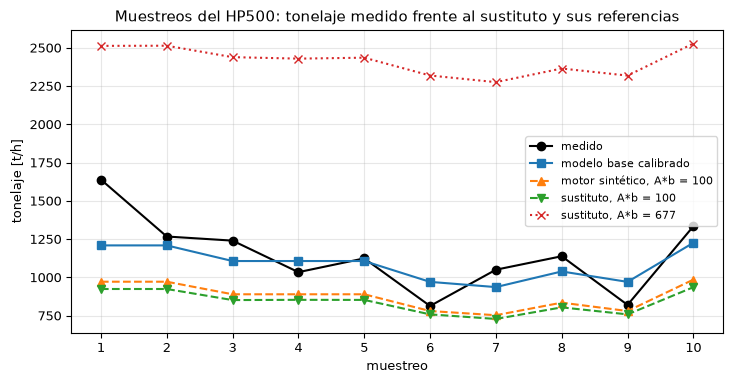

In [6]:
# Grafique el tonelaje medido y las cuatro estimaciones muestreo por muestreo
fig, ax = plt.subplots()
numbers = [s.survey for s in surveys]
ax.plot(numbers, measured, "ko-", label="medido")
ax.plot(numbers, backbone_tph, "s-", label="modelo base calibrado")
ax.plot(numbers, teacher_inside, "^--", label="motor sintético, A*b = 100")
ax.plot(numbers, network_inside, "v--", label="sustituto, A*b = 100")
ax.plot(numbers, network_outside, "x:", label="sustituto, A*b = 677")
ax.set_xticks(numbers)
ax.set_xlabel("muestreo")
ax.set_ylabel("tonelaje [t/h]")
ax.set_title("Muestreos del HP500: tonelaje medido frente al sustituto y sus referencias")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Cuatro de las cinco líneas van juntas aproximadamente al nivel de la planta, a unos cientos de t/h: el modelo base calibrado, que se ajustó a los muestreos, queda más cerca, mientras el motor sintético y el sustituto con A*b = 100 quedan bajo la medición en la mayoría de los muestreos, el sustituto entre 728,3 y 935,7 t/h. La quinta no: el sustituto con el mineral de la vía calibrada devuelve entre 2275,6 y 2528,1 t/h en cada muestreo, sobre la mayor medición (1639 t/h) en todos y unas 2,8 veces la menor (813 t/h). El error del sustituto frente a la planta, 24,78 por ciento, es el 21,72 por ciento del profesor más los 3 puntos propios de la red: la red hereda el error del profesor, sea cual sea su R cuadrado frente a él. La figura muestra que la brecha con la planta es una propiedad del profesor, no del aprendizaje.

**Dónde se rompe la red.** La quinta línea no es un problema de calibración; es una extrapolación. El rango de entrenamiento de la competencia del mineral es 30 a 110, y A*b = 677 es seis veces su borde superior. El motor lo resuelve, porque la relación t10 se satura en su tope de 0,44 y devuelve un resultado finito y ordinario; la red no tiene ese tope. La celda barre la competencia del mineral de S01, en la vía sin calibrar que la red representa, desde dentro del rango hasta muy fuera de él e imprime, para la red y para el motor, el P80 y la potencia, junto con el veredicto del autoencoder sobre el resultado del motor en cada punto.

In [7]:
# Barra la competencia del mineral de S01 desde dentro del rango de entrenamiento hasta muy fuera de él
print("A*b   P80 red    P80 motor   kW red       kW motor    alarma del autoencoder sobre el resultado del motor")
for axb in (30, 55, 110, 200, 400, 677):
    point = replace(base, ore_axb=float(axb), ore_wi=sweep.wi_of_axb(axb))
    answer = surrogate_graph(point, surrogate_bundle, models_dir)
    engine = evaluate(point)
    alarm = anomaly_graph(engine, anomaly_bundle, models_dir)["is_anomaly"]
    print(f"{axb:4d} {answer['p80_mm']:10.2f} {engine.p80:11.2f}", end="")
    print(f" {answer['power_kw']:12.1f} {engine.power_kw:11.1f}   {alarm}")

A*b   P80 red    P80 motor   kW red       kW motor    alarma del autoencoder sobre el resultado del motor
  30      28.99       29.72        305.9       309.0   False
  55      27.50       27.70        275.6       284.3   False
 110      26.70       26.85        169.3       188.1   False
 200      21.00       26.85         -8.1       169.1   False
 400      11.96       26.85       -237.4       169.1   False
 677       5.75       26.85       -548.5       169.1   False


Dentro del rango los dos coinciden. Pasado 110 el P80 de la red sigue bajando, de 26,7 mm a 5,75 mm, porque extrapola la tendencia a la baja que aprendió, mientras el del motor se queda en 26,85 mm; y su potencia pasa por cero, a -8,1 kW con A*b = 200 y -548,5 kW con 677, una potencia negativa que ninguna máquina tiene, mientras la del motor se satura en 169,1 kW. La última columna es el hallazgo de esta barrida: el autoencoder no da alarma en ninguno de los seis puntos, porque puntúa el resultado del motor, y el resultado del motor con A*b = 677 es uno ordinario. En esta barrida, una entrada sin calibrar muy fuera del rango de entrenamiento que el motor satura, la salvaguarda que el producto describe como la comprobación de fuera de distribución del sustituto es ciega. La afirmación termina ahí: es una afirmación sobre esta vía y esta barrida, y los diez muestreos, que están calibrados, necesitan su propia lectura, que viene después de la figura. La figura grafica la potencia.

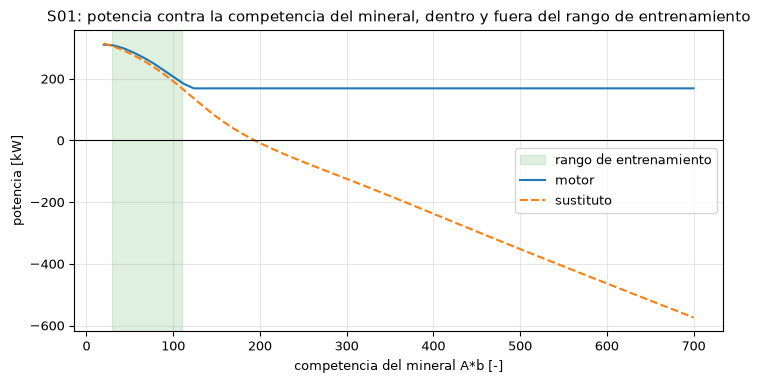

In [8]:
# Grafique la potencia de la red y del motor contra la competencia del mineral, con el rango de entrenamiento sombreado
grid = np.linspace(20, 700, 60)
points = [replace(base, ore_axb=float(a), ore_wi=sweep.wi_of_axb(a)) for a in grid]
fig, ax = plt.subplots()
ax.axvspan(*domain["ore_axb"], color="tab:green", alpha=0.15, label="rango de entrenamiento")
ax.plot(grid, [evaluate(p).power_kw for p in points], label="motor")
ax.plot(grid, [surrogate_graph(p, surrogate_bundle, models_dir)["power_kw"] for p in points], "--", label="sustituto")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("competencia del mineral A*b [-]")
ax.set_ylabel("potencia [kW]")
ax.set_title("S01: potencia contra la competencia del mineral, dentro y fuera del rango de entrenamiento")
ax.legend()
fig.tight_layout()
plt.show()

Las dos curvas coinciden en la banda verde y se separan en su borde derecho: la línea de la red cae bajo cero mientras la del motor se aplana. La figura muestra el modo de falla de un sustituto aprendido en una imagen, una extrapolación sin restricciones, y el control de envolvente del propio motor tampoco la atrapa en A*b, que el control no prueba. Lo que se sigue para el uso es simple: la red puede responder dentro de la caja de sus rangos de entrenamiento y el producto debe comprobar la caja sobre la entrada, lo que una prueba de rango hace exactamente y gratis, en vez de apoyarse en un detector de la salida.

**Qué hace el autoencoder en los muestreos.** Los puntos de los muestreos están calibrados, y el autoencoder no es ciego a ellos: sus alarmas son la pregunta de este paso. La celda puntúa el resultado del motor en los diez muestreos en tres variantes de los mismos puntos de operación: tal como son los muestreos (calibrados), con la calibración apagada en la competencia del mineral de la vía calibrada A*b = 677 (la extrapolación de la barrida de arriba), y con la calibración apagada y el mineral en A*b = 100, dentro del rango. Si las alarmas detectaran la extrapolación del mineral, seguirían a A*b; si siguen a la calibración, responden a otra cosa. Para cada variante imprime el número de alarmas, el puntaje mediano frente al umbral, y la potencia media del resultado del motor.

In [9]:
# El autoencoder en los diez muestreos: resultados calibrados, y los mismos puntos con la calibración apagada
variants = {"calibrados": calibrated, "calibración apagada, A*b = 677": far, "calibración apagada, A*b = 100": inside}
print("umbral de alarma:", anomaly_bundle["threshold_p99"])
for name, points in variants.items():
    results = [evaluate(o) for o in points]
    verdicts = [anomaly_graph(r, anomaly_bundle, models_dir) for r in results]
    scores = np.array([v["score"] for v in verdicts])
    power = np.mean([r.power_kw for r in results])
    alarms = sum(v["is_anomaly"] for v in verdicts)
    print(f"{name:32s} alarmas {alarms:2d} de 10 | puntaje mediano {np.median(scores):.3f}", end=" ")
    print(f"| potencia media {power:6.1f} kW")

umbral de alarma: 0.24454
calibrados                       alarmas  8 de 10 | puntaje mediano 0.299 | potencia media  401.1 kW
calibración apagada, A*b = 677   alarmas  0 de 10 | puntaje mediano 0.086 | potencia media  133.7 kW
calibración apagada, A*b = 100   alarmas  0 de 10 | puntaje mediano 0.074 | potencia media  145.6 kW


El autoencoder da alarma en 8 de los 10 resultados calibrados, y en ninguno de los mismos diez puntos una vez apagada la calibración, ya sea que el mineral esté en el A*b = 677 calibrado o dentro del rango de entrenamiento en 100. Las alarmas, por tanto, no detectan la extrapolación del mineral, que es la misma en las dos primeras variantes; responden a la firma del resultado de la vía calibrada. La columna de potencia media muestra una diferencia de la firma: la forma calibrada $1{,}30\,P_d + 110$ kW pone la potencia del resultado en cerca de tres veces el nivel del motor sin calibrar, una combinación que el barrido de entrenamiento quizá nunca produjo. Este notebook no aísla la potencia, porque la vía calibrada también cambia el P80 y el tonelaje (el notebook 02 del tema 05 compara las dos vías), así que la potencia es la mayor diferencia en términos relativos y no una causa demostrada: el autoencoder lee la firma completa como fuera del dominio. La alarma en los muestreos es real y correcta por una razón equivocada: marca que los resultados no son del tipo que la red emula, y no dice nada sobre el mineral, así que no puede ofrecerse como el detector de extrapolación que la barrida de arriba mostró que no es.

**La regla que la rechaza.** El producto no deja esa prueba de rango al lector. Los dos contratos de modelo registran el rango de entrenamiento de cada entrada continua para cada máquina (`training.input_ranges`, escrito por la etapa de entrenamiento a partir de los rangos del propio barrido), y una sola regla de aplicabilidad decide, igual en el pipeline y en el navegador: un modelo aplica a un punto de operación solo cuando el punto no está calibrado, porque los modelos emulan el motor sin calibrar, y cada entrada continua queda dentro del rango de su máquina. Donde no aplica, responde la línea base de la ranura, rotulada con la razón: el motor para el sustituto, el control de envolvente para el autoencoder. La celda pregunta a las ranuras, por las envolturas del pipeline, lo que arriba respondió la red cruda.

In [10]:
# Pregunte a la ranura, con la regla de aplicabilidad, por los muestreos y por los mismos puntos sin calibración
verdicts = [applicability(o, surrogate_bundle) for o in calibrated]
refused = sum(not ok for ok, _ in verdicts)
print("muestreos que la regla rechaza:", refused, "de 10 | razones:", dict(Counter(tuple(r) for _, r in verdicts)))
uncalibrated = [replace(o, calibrated=False) for o in calibrated]
reasons = Counter(tuple(applicability(o, surrogate_bundle)[1]) for o in uncalibrated)
print("los mismos puntos con la calibración apagada:", dict(reasons))
slot_answers = [surrogate_predict(o, models_dir) for o in calibrated]
print("procedencia de la ranura del sustituto en los diez muestreos:", dict(Counter(p for _, p in slot_answers)))
own = all(a == engine_outputs(evaluate(o)) for (a, _), o in zip(slot_answers, calibrated))
print("la respuesta de la ranura es la del propio motor en cada muestreo:", own)
raw_power = surrogate_graph(calibrated[0], surrogate_bundle, models_dir)["power_kw"]
slot_power = round(slot_answers[0][0]["power_kw"], 1)
print("potencia en el muestreo 1 [kW], ranura:", slot_power, "| red cruda:", round(raw_power, 1))
anomaly_slot = [anomaly_score(evaluate(o), models_dir) for o in calibrated]
print("procedencia de la ranura del autoencoder en los diez muestreos:", dict(Counter(p for _, p in anomaly_slot)))
print("claves de la respuesta de la ranura del autoencoder:", sorted(anomaly_slot[0][0]))

muestreos que la regla rechaza: 10 de 10 | razones: {('calibrated_case',): 10}
los mismos puntos con la calibración apagada: {('outside_training_range:ore_axb',): 8, ('outside_training_range:feed_x63_mm', 'outside_training_range:ore_axb'): 2}
procedencia de la ranura del sustituto en los diez muestreos: {'baseline': 10}
la respuesta de la ranura es la del propio motor en cada muestreo: True
potencia en el muestreo 1 [kW], ranura: 408.3 | red cruda: -572.8
procedencia de la ranura del autoencoder en los diez muestreos: {'baseline': 10}
claves de la respuesta de la ranura del autoencoder: ['is_anomaly']


La regla rechaza los diez muestreos, cada uno por una sola razón, `calibrated_case`: corren el ajuste calibrado y los modelos emulan el motor sin calibrar. Con la calibración apagada los mismos puntos seguirían rechazados, ocho solo por la competencia del mineral y dos (muestreos 3 y 5) también por el tamaño de la alimentación, la lista que imprimió la celda anterior. La ranura del sustituto responde entonces cada muestreo con los valores del propio motor y la procedencia `baseline`: en el muestreo 1 da 408,3 kW donde la red cruda da -572,8 kW. La ranura del autoencoder hace lo mismo: su respuesta es solo el veredicto del control de envolvente, sin puntaje. Los lectores crudos quedan en este notebook como la evidencia de por qué existe la regla; las vistas del producto y su generación nunca muestran sus números en un punto que la regla rechaza.

## Resultados

**Respuesta:** el enfoque del sustituto es preciso frente a su profesor, y dice de la planta lo que dice el profesor: en una muestra independiente pequeña de 276 puntos su puntaje de muestra de prueba es R cuadrado 0,9971 para P80 y 0,9984 para el tonelaje. En los diez muestreos, con el mineral en el borde del rango de entrenamiento, el error absoluto medio de tonelaje del sustituto frente a la medición es 24,78 por ciento, el del motor sintético 21,72 y el del modelo base calibrado 11,55: la red hereda el error del profesor y agrega unos 3 puntos. Alimentada con el mineral de la vía calibrada, A*b = 677 frente a un rango de entrenamiento de 30 a 110, devuelve entre 2275,6 y 2528,1 t/h en cada muestreo (118,20 por ciento de error medio) y, en el muestreo 1, una potencia de -572,8 kW donde el motor da 408,3 kW.

Los dos comportamientos del autoencoder deben mantenerse separados. En la barrida de A*b sin calibrar de S01 no da alarma en ninguno de los seis puntos, porque el resultado del motor allí es ordinario: ante una entrada muy fuera del rango de entrenamiento que el motor satura, es ciego. En los diez muestreos calibrados da alarma en 8 de 10, pero no la da en los mismos diez puntos con la calibración apagada, ni con A*b = 677 (0 de 10) ni con 100 (0 de 10), donde la potencia media del resultado es 133,7 y 145,6 kW frente a 401,1 kW calibrado. Sus alarmas en los muestreos responden por tanto a la firma de la vía calibrada, y no son una detección de la extrapolación del mineral.

La primera figura muestra que la brecha con la planta es la del profesor, la segunda la falla pasado el rango. Un validador concluiría que un R cuadrado de muestra de prueba valida la emulación y nada más, que el sustituto del producto debe protegerse sobre su rango de entrada y no solo con un detector de la salida, y que la vía real, calibrada y medida, es la evidencia que aporta a la planta el motor y no la red. El producto aplica entonces la prueba de rango sobre la entrada: sus dos contratos registran los rangos de entrenamiento, y una sola regla, igual en el pipeline y en el navegador, rechaza el sustituto y el autoencoder en los diez muestreos, así que allí responden el motor y el control de envolvente, rotulados con la razón. Son las conclusiones de una medición sobre la red propia del producto; las cifras del artículo para su propio circuito no se prueban aquí.

## Resumen

El enfoque del sustituto aprendido se valida frente al modelo que emula, y la red del producto cumple esa vara; lo que dice de la planta es lo que dice su profesor, algo peor. La red extrapola sin límite fuera de su caja de entrenamiento, y el autoencoder no lo ve cuando el motor se satura; sus alarmas en los muestreos pertenecen a la firma de la vía calibrada y no al mineral. Una prueba de rango sobre la entrada sí ve la extrapolación, y el producto ya ejecuta esa prueba, desde los rangos que registran sus contratos, y responde con el motor o el control de envolvente donde los modelos no aplican. Para la planta, la vía calibrada del motor y su validación con datos retenidos (tema 06) son la evidencia, y el sustituto es una aproximación rápida para usar dentro de su caja.

## Referencias

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919